# 01 · Data, quality checks and exploratory analysis

**Goal:** understand the freMTPL2 French motor portfolio (≈680k policies) before modelling anything.

In pricing we model two things separately and multiply them:

| Component | Target | Typical model |
|---|---|---|
| **Frequency** | claims per year of exposure | Poisson GLM / GBM |
| **Severity** | average cost *per claim* | Gamma GLM / GBM |
| **Pure premium** | frequency × severity = expected loss per policy-year | (what we price on) |

**Exposure** is the fraction of a year a policy was on risk. A policy with 3 months of cover has `Exposure=0.25`,
so it is *expected* to generate a quarter of the claims of a full-year policy. Ignoring exposure is the #1 beginner mistake.

> First run downloads the data from OpenML (needs internet, ~30 MB) and caches it in `data/`.

In [2]:
%load_ext autoreload
%autoreload 2
import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from motor_pricing.data import load_data, split_data, validate

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", "{:,.4f}".format)
pd.set_option("display.max_columns", 30)

## 1. Load the cleaned dataset
`load_data()` merges the frequency and severity tables and applies the cleaning rules documented in
`src/motor_pricing/data.py`:
1. claims reported but **no amount** recorded → treated as no claim;
2. an amount recorded but **no claim counted** → at least one claim;
3. `ClaimNb` capped at 4, `Exposure` capped at 1 year, total `ClaimAmount` capped at €200k per policy (extreme-loss truncation).

In [3]:
import pandera as pa
from pandera import Column, DataFrameSchema

schema = DataFrameSchema({
    "VehGas": Column(
        pa.String,
        checks=pa.Check.isin(["Diesel", "Regular"]),
        nullable=True
    ),
})

In [5]:
df = load_data()
print(f"{df.shape[0]:,} policies x {df.shape[1]} columns")
df.head()

678,013 policies x 13 columns


,IDpol,ClaimNb,Exposure,ClaimAmount,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region
0,1,0,0.1000,0.0000,D,5,0,55,50,B12,Regular,"1,217.0000",R82
1,3,0,0.7700,0.0000,D,5,0,55,50,B12,Regular,"1,217.0000",R82
2,5,0,0.7500,0.0000,B,6,2,52,50,B12,Diesel,54.0000,R22
3,10,0,0.0900,0.0000,B,7,0,46,50,B12,Diesel,76.0000,R72
4,11,0,0.8400,0.0000,B,7,0,46,50,B12,Diesel,76.0000,R72


## 2. Portfolio KPIs

In [6]:
expo = df["Exposure"].sum()
claims = df["ClaimNb"].sum()
kpis = pd.Series({
    "policies": len(df),
    "exposure (policy-years)": expo,
    "claims": claims,
    "claim frequency (per year)": claims / expo,
    "average severity": df["ClaimAmount"].sum() / claims,
    "pure premium (loss per policy-year)": df["ClaimAmount"].sum() / expo,
    "share of policies with a claim": (df["ClaimNb"] > 0).mean(),
})
kpis.to_frame("value")

,value
policies,"678,013.0000"
exposure (policy-years),"358,360.1055"
claims,"26,406.0000"
claim frequency (per year),0.0737
average severity,"1,975.7493"
pure premium (loss per policy-year),145.5844
share of policies with a claim,0.0368


## 3. Data-quality checks
A pricing model is only as good as its data. These checks also run in the test-suite (`pytest`).

In [7]:
checks = pd.Series({
    "duplicate policy IDs": int(df["IDpol"].duplicated().sum()),
    "missing values": int(df.isna().sum().sum()),
    "exposure <= 0": int((df["Exposure"] <= 0).sum()),
    "exposure > 1 year": int((df["Exposure"] > 1).sum()),
    "claims but no amount": int(((df["ClaimNb"] > 0) & (df["ClaimAmount"] == 0)).sum()),
    "amount but no claims": int(((df["ClaimNb"] == 0) & (df["ClaimAmount"] > 0)).sum()),
    "policies with exposure < 1 week": int((df["Exposure"] < 7 / 365).sum()),
})
display(checks.to_frame("count"))
validate(df)  # raises a pandera SchemaError if any schema rule is violated
print("pandera schema validation passed ✔")

,count
duplicate policy IDs,0
missing values,0
exposure <= 0,0
exposure > 1 year,0
claims but no amount,0
amount but no claims,0
policies with exposure < 1 week,13603


pandera schema validation passed ✔


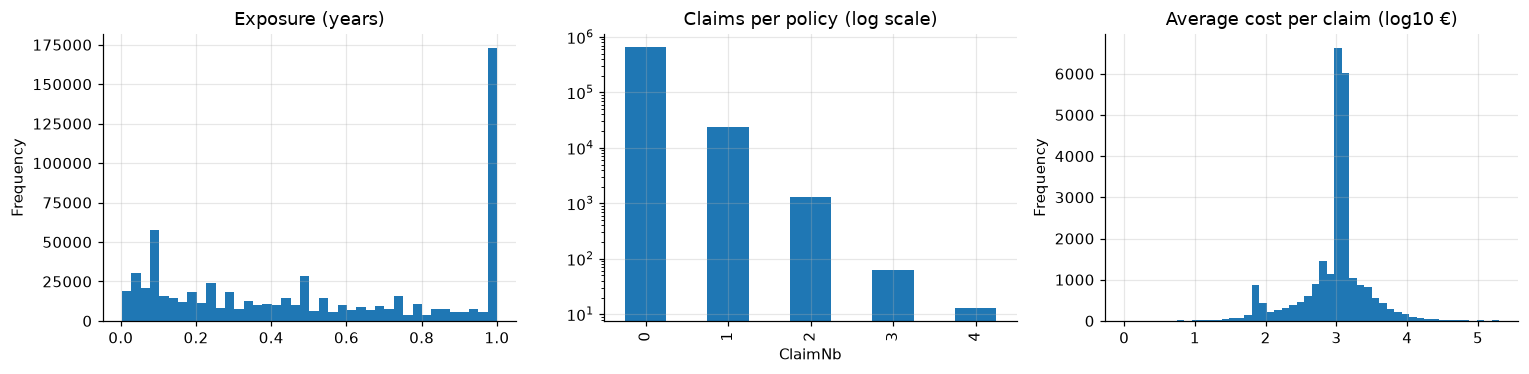

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
df["Exposure"].plot.hist(bins=40, ax=axes[0], title="Exposure (years)")
df["ClaimNb"].value_counts().sort_index().plot.bar(ax=axes[1], logy=True, title="Claims per policy (log scale)")
sev = df.loc[df["ClaimNb"] > 0, "ClaimAmount"] / df.loc[df["ClaimNb"] > 0, "ClaimNb"]
np.log10(sev.clip(lower=1)).plot.hist(bins=50, ax=axes[2], title="Average cost per claim (log10 €)")
plt.tight_layout()

**Reading the charts:** many policies have partial-year exposure (so we *must* use an offset / weights); the vast majority
of policies have zero claims (hence Poisson, not a normal-error model); severity is heavily right-skewed (hence Gamma with a log link).

## 4. Risk drivers: one variable at a time
Bars show the share of exposure in each level (so you can see how credible each point is);
the line shows the observed **claim frequency** (claims ÷ exposure).

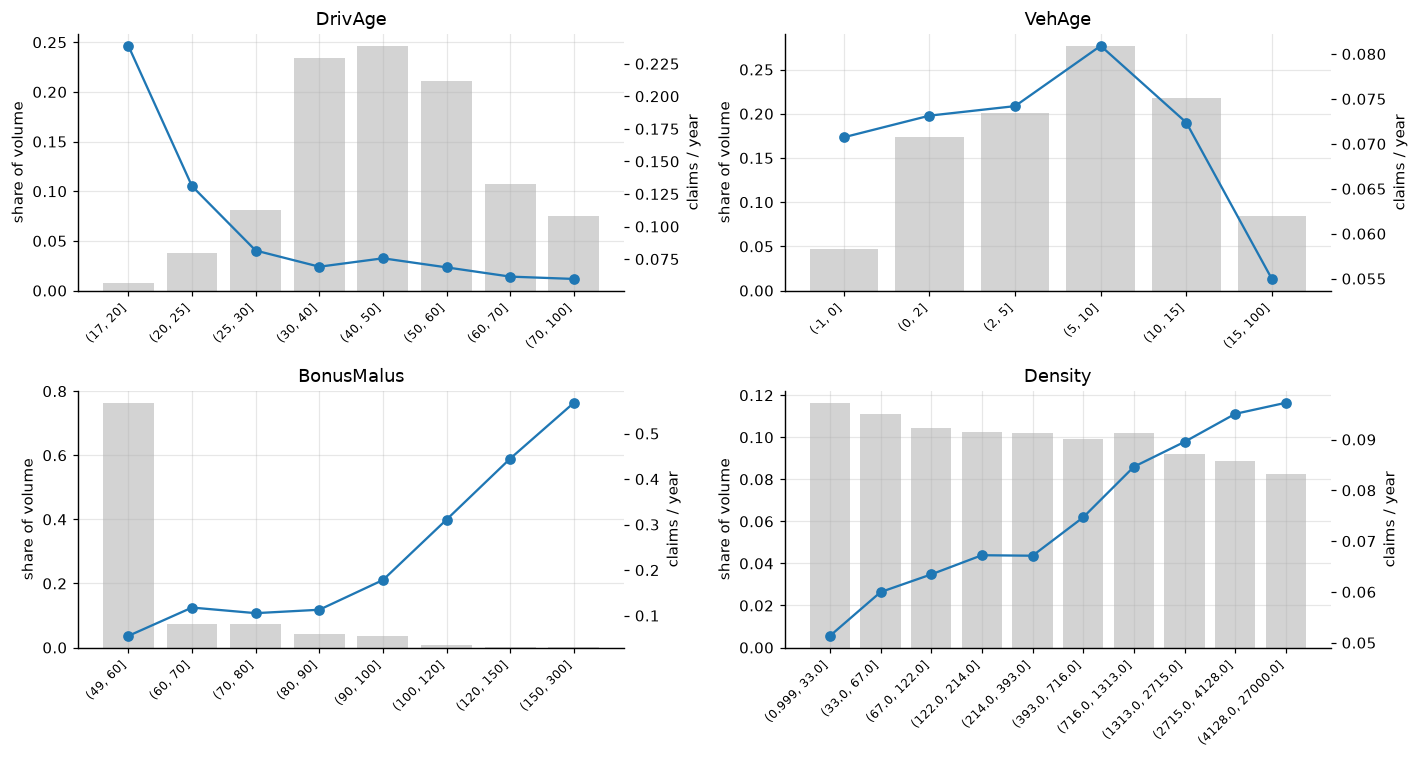

In [9]:
def rate_plot(data, col, num, den, bins=None, qcut=None, ylabel="", ax=None, order=None):
    if bins is not None:
        key = pd.cut(data[col], bins)
    elif qcut is not None:
        key = pd.qcut(data[col], qcut, duplicates="drop")
    else:
        key = data[col]
    t = data.groupby(key, observed=True).agg(n=(num, "sum"), d=(den, "sum"))
    if order is not None:
        t = t.reindex(order)
    t["rate"] = t["n"] / t["d"]
    ax = ax or plt.gca()
    x = np.arange(len(t))
    ax.bar(x, t["d"] / t["d"].sum(), color="lightgrey", label="share of volume")
    ax.set_xticks(x)
    ax.set_xticklabels([str(i) for i in t.index], rotation=45, ha="right", fontsize=8)
    ax.set_title(col)
    ax.set_ylabel("share of volume")
    ax2 = ax.twinx()
    ax2.plot(x, t["rate"], marker="o", color="C0")
    ax2.set_ylabel(ylabel)
    ax2.grid(False)
    return t


panels = {
    "DrivAge": dict(bins=[17, 20, 25, 30, 40, 50, 60, 70, 100]),
    "VehAge": dict(bins=[-1, 0, 2, 5, 10, 15, 100]),
    "BonusMalus": dict(bins=[49, 60, 70, 80, 90, 100, 120, 150, 300]),
    "Density": dict(qcut=10),
}
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for ax, (col, kw) in zip(axes.ravel(), panels.items(), strict=True):
    rate_plot(df, col, "ClaimNb", "Exposure", ylabel="claims / year", ax=ax, **kw)
plt.tight_layout()

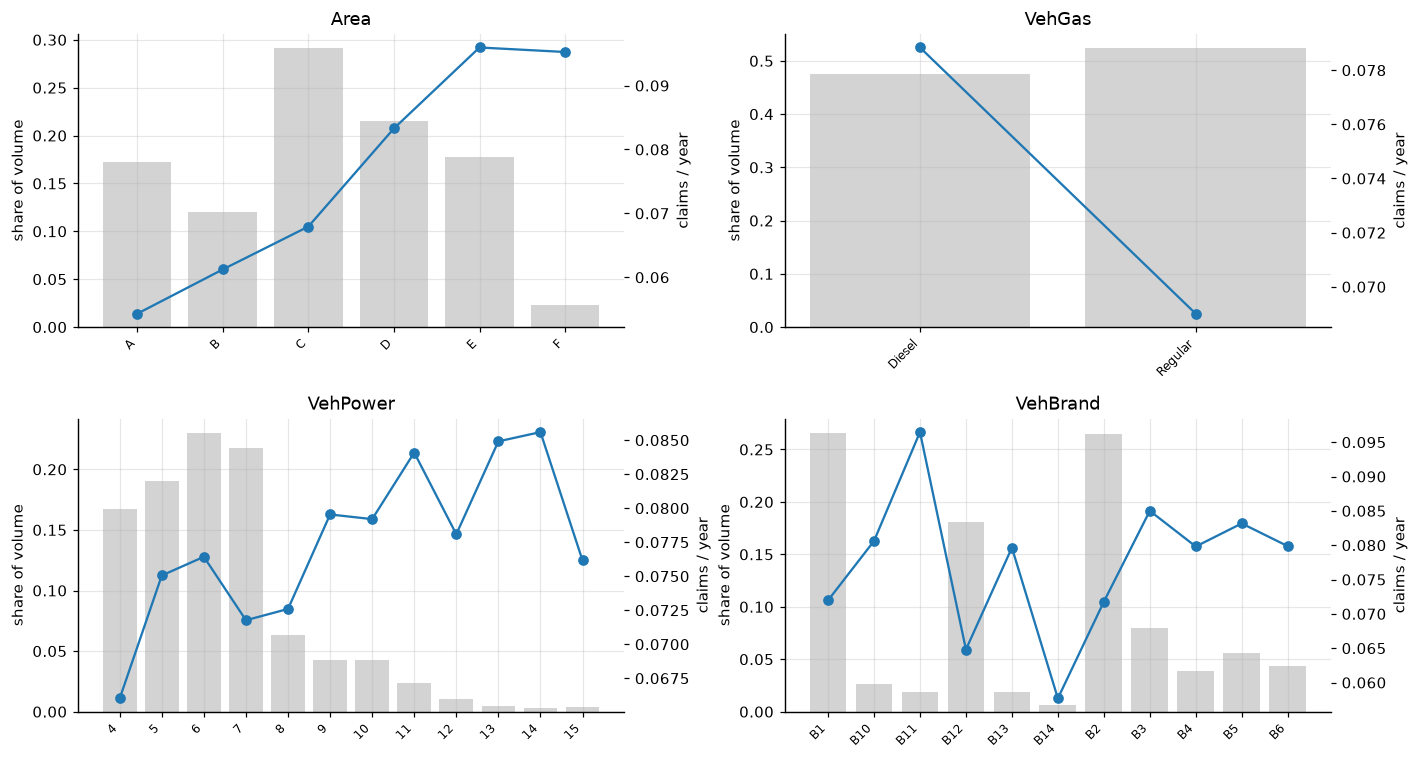

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for ax, col in zip(axes.ravel(), ["Area", "VehGas", "VehPower", "VehBrand"], strict=True):
    rate_plot(df, col, "ClaimNb", "Exposure", ylabel="claims / year", ax=ax)
plt.tight_layout()

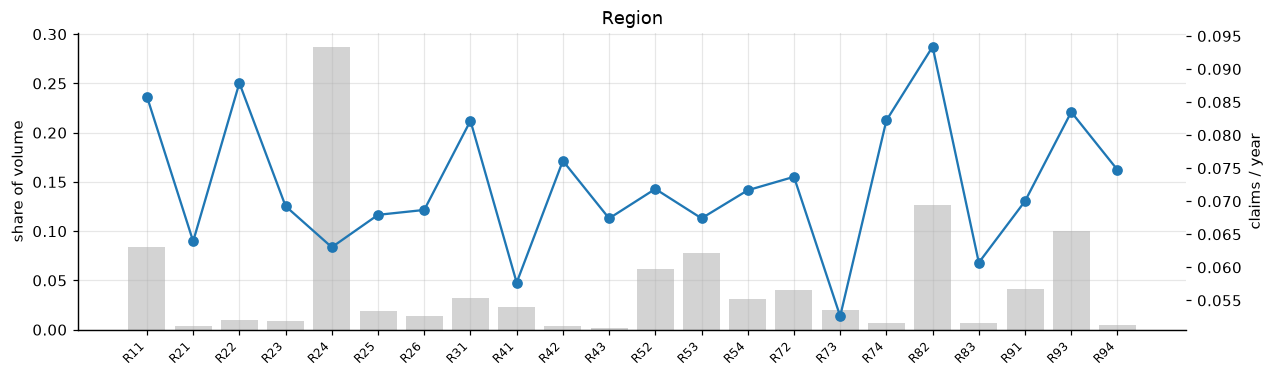

In [11]:
fig, ax = plt.subplots(figsize=(13, 3.5))
_ = rate_plot(df, "Region", "ClaimNb", "Exposure", ylabel="claims / year", ax=ax)

### Severity drivers (claims only)
Average cost per claim, weighted by number of claims. Expect **much weaker** signal than for frequency — this is normal in motor insurance.

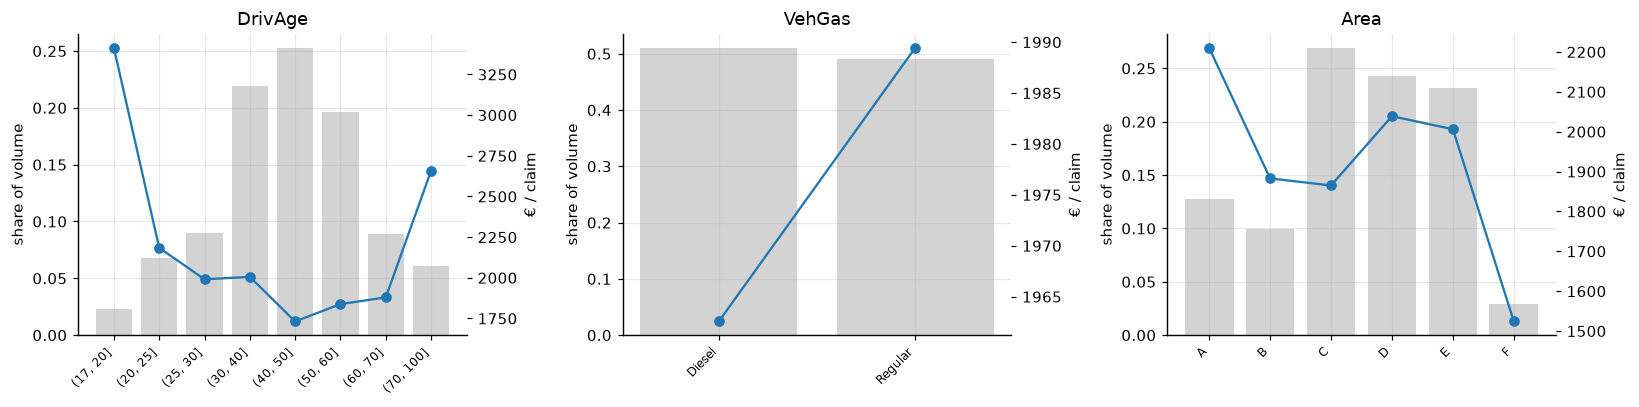

In [12]:
cl = df[df["ClaimNb"] > 0]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
rate_plot(cl, "DrivAge", "ClaimAmount", "ClaimNb", bins=panels["DrivAge"]["bins"], ylabel="€ / claim", ax=axes[0])
rate_plot(cl, "VehGas", "ClaimAmount", "ClaimNb", ylabel="€ / claim", ax=axes[1])
rate_plot(cl, "Area", "ClaimAmount", "ClaimNb", ylabel="€ / claim", ax=axes[2])
plt.tight_layout()

## 5. Train / validation / test split
* **Train (70%)** – fit models. **Validation (15%)** – early stopping & hyper-parameter tuning. **Test (15%)** – touched *once* at the end.
* freMTPL2 has one row per policy and **no date**, so there are no repeated customers to group on and no time axis to split on →
  a *stratified random split* (on claim / no-claim) is appropriate. With real company data, split by **underwriting year** to
  mimic how the model is actually used (trained on the past, priced on the future).

In [13]:
train, valid, test = split_data(df)
pd.DataFrame({
    "policies": [len(s) for s in (train, valid, test)],
    "exposure": [s["Exposure"].sum() for s in (train, valid, test)],
    "claim frequency": [s["ClaimNb"].sum() / s["Exposure"].sum() for s in (train, valid, test)],
    "pure premium": [s["ClaimAmount"].sum() / s["Exposure"].sum() for s in (train, valid, test)],
}, index=["train", "valid", "test"])

,policies,exposure,claim frequency,pure premium
train,474609,"250,872.5475",0.0736,148.2488
valid,101702,"53,943.6615",0.0738,137.6197
test,101702,"53,543.8964",0.0741,141.1248


## Takeaways to write in your README
* Frequency varies strongly with driver age (young drivers), bonus-malus and (to a lesser degree) vehicle age and density.
* Exposure is heterogeneous → every model below uses an exposure offset (GLM) or exposure weights (GBM).
* Severity is noisy and weakly predictable → keep that model simple and strongly regularised.
* Next: **`02_glm_baselines.ipynb`** — the industry-standard benchmark we must beat.